In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn

from PIL import Image
from tqdm import tqdm
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, precision_score, recall_score
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from transformers import AutoImageProcessor, AutoModel

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    auc
)

# 1. Configuration

In [ ]:
DATA_PATH = "/kaggle/input/datasets/jeffreyjoemathews/ff-30frames-mtcnn/FF++(MTCNN)/data_mtcnn"

# Number of frames used per video
NUM_FRAMES = 30

# Image size
IMG_SIZE = 224

# Training parameters for the DATA LOADER only
BATCH_SIZE = 4
NUM_WORKERS = 2

# Reproducibility
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("Dataset path:", DATA_PATH)
print("Number of frames:", NUM_FRAMES)
print("Image size:", IMG_SIZE)

Dataset path: /kaggle/input/datasets/jeffreyjoemathews/ff-30frames-mtcnn/FF++(MTCNN)/data_mtcnn
Number of frames: 30
Image size: 224


# 2. Class Mapping

In [ ]:
CLASSES_DICT = {
    "original": 0,
    "DeepFakeDetection": 1,
    "Deepfakes": 1,
    "Face2Face": 1,
    "FaceShifter": 1,
    "FaceSwap": 1,
    "NeuralTextures": 1,
}

# 3. Image Transformation

In [ ]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# 4. Scan Dataset

In [ ]:
def get_samples_from_path(base_path):
    samples = []
    primary_ids = set()
    for folder_name, label in CLASSES_DICT.items():
        folder_path = os.path.join(base_path, folder_name)
        if not os.path.exists(folder_path):
            print(f"[WARNING] Folder not found: {folder_path}")
            continue
        files = [
            f for f in os.listdir(folder_path)
            if f.endswith("_frame0.jpg")
        ]
        print(
            f"{folder_name:20s} | "
            f"videos found: {len(files)}"
        )
        for file in files:
            prefix = file.split("_frame")[0]
            primary_id = prefix.split("_")[0]
            primary_ids.add(primary_id)
            samples.append(
                (
                    folder_path,
                    prefix,
                    label,
                    primary_id
                )
            )
    return samples, sorted(list(primary_ids))

# 5. Scan FF++

In [ ]:
print("\n" + "=" * 60)
print("SCANNING FF++ DATASET")
print("=" * 60)

all_samples, all_primary_ids = get_samples_from_path(DATA_PATH)

print("\nTotal video samples:", len(all_samples))
print("Total primary IDs:", len(all_primary_ids))


SCANNING FF++ DATASET
original             | videos found: 1000
DeepFakeDetection    | videos found: 1000
Deepfakes            | videos found: 1000
Face2Face            | videos found: 1000
FaceShifter          | videos found: 1000
FaceSwap             | videos found: 1000
NeuralTextures       | videos found: 1000

Total video samples: 7000
Total primary IDs: 1028


# 6. Check REAL / FAKE Balance

In [ ]:
real_samples = [
    sample for sample in all_samples
    if sample[2] == 0
]

fake_samples = [
    sample for sample in all_samples
    if sample[2] == 1
]

print("\nDataset distribution:")
print(f"REAL videos : {len(real_samples)}")
print(f"FAKE videos : {len(fake_samples)}")


Dataset distribution:
REAL videos : 1000
FAKE videos : 6000


# 7. Split by Primary ID

In [ ]:
train_ids, test_ids = train_test_split(
    all_primary_ids,
    test_size=0.15,
    random_state=RANDOM_SEED
)

train_ids, val_ids = train_test_split(
    train_ids,
    test_size=0.15,
    random_state=RANDOM_SEED
)

train_ids = set(train_ids)
val_ids = set(val_ids)
test_ids = set(test_ids)

print("\n" + "=" * 60)
print("DATA SPLIT")
print("=" * 60)

print("Train IDs:", len(train_ids))
print("Validation IDs:", len(val_ids))
print("Test IDs:", len(test_ids))


DATA SPLIT
Train IDs: 742
Validation IDs: 131
Test IDs: 155


# 8. Dataset Class

In [ ]:
class FFPlusPlusDataset(Dataset):
    def __init__(
        self,
        samples,
        allowed_ids,
        num_frames=10,
        transform=None
    ):
        self.samples = [
            sample
            for sample in samples
            if sample[3] in allowed_ids
        ]
        self.num_frames = num_frames
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        folder_path, prefix, label, primary_id = self.samples[idx]
        frames = []
        for frame_idx in range(self.num_frames):
            image_path = os.path.join(
                folder_path,
                f"{prefix}_frame{frame_idx}.jpg"
            )
            if os.path.exists(image_path):
                with Image.open(image_path) as image:
                    image = image.convert("RGB")
                    if self.transform is not None:
                        image = self.transform(image)
                frames.append(image)
            else:
                # Missing frame → zero tensor
                frames.append(
                    torch.zeros(
                        3,
                        IMG_SIZE,
                        IMG_SIZE,
                        dtype=torch.float32
                    )
                )
        # [T, C, H, W]
        frames = torch.stack(frames)
        label = torch.tensor(
            label,
            dtype=torch.float32
        )
        return frames, label

# 9. Create Datasets

In [ ]:
train_dataset = FFPlusPlusDataset(
    samples=all_samples,
    allowed_ids=train_ids,
    num_frames=NUM_FRAMES,
    transform=transform
)

val_dataset = FFPlusPlusDataset(
    samples=all_samples,
    allowed_ids=val_ids,
    num_frames=NUM_FRAMES,
    transform=transform
)

test_dataset = FFPlusPlusDataset(
    samples=all_samples,
    allowed_ids=test_ids,
    num_frames=NUM_FRAMES,
    transform=transform
)

# 10. Create Dataloaders

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

# 11. Dataset Summary

In [ ]:
print("\n" + "=" * 60)
print("FINAL DATASET SIZES")
print("=" * 60)

print(f"Training   : {len(train_dataset)} videos")
print(f"Validation : {len(val_dataset)} videos")
print(f"Testing    : {len(test_dataset)} videos")


FINAL DATASET SIZES
Training   : 5047 videos
Validation : 879 videos
Testing    : 1074 videos


# 12. Check ONE SAMPLE

In [ ]:
sample_frames, sample_label = train_dataset[0]

print("\n" + "=" * 60)
print("SAMPLE CHECK")
print("=" * 60)

print("Frames shape :", sample_frames.shape)
print("Label        :", sample_label.item())

print("\nExpected:")
print(f"Frames shape : [{NUM_FRAMES}, 3, {IMG_SIZE}, {IMG_SIZE}]")
print("Label        : 0 = REAL / 1 = FAKE")


SAMPLE CHECK
Frames shape : torch.Size([30, 3, 224, 224])
Label        : 0.0

Expected:
Frames shape : [30, 3, 224, 224]
Label        : 0 = REAL / 1 = FAKE


# 13. Check ONE BATCH

In [ ]:
videos, labels = next(iter(train_loader))

print("\n" + "=" * 60)
print("BATCH CHECK")
print("=" * 60)

print("Video batch shape :", videos.shape)
print("Label batch shape :", labels.shape)

print("\nExpected:")
print(
    f"Video batch shape : "
    f"[{BATCH_SIZE}, {NUM_FRAMES}, 3, {IMG_SIZE}, {IMG_SIZE}]"
)
print(
    f"Label batch shape : [{BATCH_SIZE}]"
)


BATCH CHECK
Video batch shape : torch.Size([4, 30, 3, 224, 224])
Label batch shape : torch.Size([4])

Expected:
Video batch shape : [4, 30, 3, 224, 224]
Label batch shape : [4]


# 14. Load DINOv2-SMALL

In [ ]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(
        i,
        torch.cuda.get_device_name(i)
    )

DINO_MODEL_NAME = "facebook/dinov2-small"

print("Loading DINOv2...")

dino_processor = AutoImageProcessor.from_pretrained(
    DINO_MODEL_NAME
)

dino = AutoModel.from_pretrained(
    DINO_MODEL_NAME
)

dino = dino.to(DEVICE)
dino.eval()

# Freeze DINOv2 completely
for param in dino.parameters():
    param.requires_grad = False

print("DINOv2 loaded successfully.")
print(
    "Hidden dimension:",
    dino.config.hidden_size
)

CUDA available: True
GPU count: 2
0 Tesla T4
1 Tesla T4
Loading DINOv2...


preprocessor_config.json:   0%|          | 0.00/436 [00:00<?, ?B/s]

The image processor of type `BitImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

DINOv2 loaded successfully.
Hidden dimension: 384


# 15. B2 Spatial Feature Extractor

In [ ]:
class B2SpatialTemporalExtractor(nn.Module):

    def __init__(self, dino_model):

        super().__init__()

        self.dino = dino_model

        # ====================================================
        # DINOv2 is completely frozen
        # ====================================================

        for param in self.dino.parameters():
            param.requires_grad = False

        # ====================================================
        # SPATIAL ENCODER
        #
        # Input:
        # [B*T, 384, 16, 16]
        #
        # We intentionally DO NOT spatially pool here.
        # ====================================================

        self.spatial_projection = nn.Sequential(

            # 384 → 192
            nn.Conv2d(
                384,
                192,
                kernel_size=1,
                bias=False
            ),

            nn.BatchNorm2d(192),

            nn.GELU()
        )

        # ====================================================
        # Local spatial processing
        #
        # Depthwise convolution preserves:
        #
        # [192,16,16]
        #
        # while allowing neighbouring patches to interact.
        # ====================================================

        self.spatial_depthwise = nn.Conv2d(
            192,
            192,
            kernel_size=3,
            padding=1,
            groups=192,
            bias=False
        )

        self.spatial_norm = nn.BatchNorm2d(192)

        # ====================================================
        # Spatial residual refinement
        # ====================================================

        self.spatial_refinement = nn.Sequential(

            nn.Conv2d(
                192,
                192,
                kernel_size=1,
                bias=False
            ),

            nn.BatchNorm2d(192),

            nn.GELU()
        )

        # ====================================================
        # TEMPORAL MODULE
        #
        # Input:
        #
        # [B,192,T,16,16]
        #
        # Notice:
        # spatial dimensions are STILL PRESENT.
        #
        # Temporal kernel = 3
        # Spatial kernel = 1x1
        #
        # This learns temporal changes at each spatial
        # patch location.
        # ====================================================

        self.temporal_depthwise = nn.Conv3d(
            192,
            192,
            kernel_size=(3, 1, 1),
            padding=(1, 0, 0),
            groups=192,
            bias=False
        )

        self.temporal_norm = nn.BatchNorm3d(192)

        # ====================================================
        # Channel mixing after temporal processing
        #
        # 192 → 128
        #
        # This is the first channel compression.
        # ====================================================

        self.temporal_projection = nn.Sequential(

            nn.Conv3d(
                192,
                128,
                kernel_size=1,
                bias=False
            ),

            nn.BatchNorm3d(128),

            nn.GELU()
        )

        # ====================================================
        # Temporal gate
        #
        # Learns which temporal positions contain useful
        # forensic information.
        #
        # Input:
        # [B,128,T,16,16]
        #
        # Output:
        # [B,1,T,16,16]
        # ====================================================

        self.temporal_gate = nn.Sequential(

            nn.Conv3d(
                128,
                32,
                kernel_size=1
            ),

            nn.GELU(),

            nn.Conv3d(
                32,
                1,
                kernel_size=1
            )
        )

        # ====================================================
        # SPATIAL ATTENTION
        #
        # This happens AFTER temporal processing.
        #
        # Therefore spatial information survives the entire
        # temporal stage.
        # ====================================================

        self.spatial_attention = nn.Sequential(

            nn.Conv2d(
                128,
                32,
                kernel_size=1
            ),

            nn.GELU(),

            nn.Conv2d(
                32,
                1,
                kernel_size=1
            )
        )

    @torch.no_grad()
    def extract_dino_tokens(self, videos):

        B, T, C, H, W = videos.shape

        # ----------------------------------------------------
        # [B,T,C,H,W]
        #        ↓
        # [B*T,C,H,W]
        # ----------------------------------------------------

        frames = videos.reshape(
            B * T,
            C,
            H,
            W
        ).to(DEVICE)

        # ----------------------------------------------------
        # DINOv2
        #
        # [B*T,3,224,224]
        #        ↓
        # [B*T,257,384]
        # ----------------------------------------------------

        outputs = self.dino(
            pixel_values=frames
        )

        # Remove CLS token
        #
        # [B*T,257,384]
        #        ↓
        # [B*T,256,384]

        patch_tokens = (
            outputs.last_hidden_state[:, 1:, :]
        )

        return patch_tokens

    def forward(self, videos):

        B, T, C, H, W = videos.shape

        # ====================================================
        # 1. DINOv2 PATCH FEATURES
        # ====================================================

        with torch.no_grad():

            patch_tokens = self.extract_dino_tokens(
                videos
            )

        # ====================================================
        # 2. RESTORE 2D PATCH GRID
        #
        # [B*T,256,384]
        #        ↓
        # [B*T,384,256]
        #        ↓
        # [B*T,384,16,16]
        #
        # IMPORTANT:
        # No spatial pooling.
        # ====================================================

        x = patch_tokens.transpose(
            1,
            2
        )

        x = x.reshape(
            B * T,
            384,
            16,
            16
        )

        # ====================================================
        # 3. SPATIAL CHANNEL PROJECTION
        #
        # [B*T,384,16,16]
        #        ↓
        # [B*T,192,16,16]
        # ====================================================

        x = self.spatial_projection(x)

        # ====================================================
        # 4. LOCAL SPATIAL PROCESSING
        # ====================================================

        residual = x

        x = self.spatial_depthwise(x)

        x = self.spatial_norm(x)

        x = x + residual

        x = self.spatial_refinement(x)

        # ====================================================
        # Restore temporal dimension
        #
        # [B*T,192,16,16]
        #        ↓
        # [B,T,192,16,16]
        # ====================================================

        x = x.reshape(
            B,
            T,
            192,
            16,
            16
        )

        # ====================================================
        # 5. CONVERT TO CONV3D FORMAT
        #
        # Conv3D expects:
        #
        # [B,C,D,H,W]
        #
        # We use:
        #
        # D = temporal dimension
        #
        # [B,T,192,16,16]
        #        ↓
        # [B,192,T,16,16]
        # ====================================================

        x = x.permute(
            0,
            2,
            1,
            3,
            4
        )

        # ====================================================
        # 6. TEMPORAL DEPTHWISE PROCESSING
        #
        # [B,192,T,16,16]
        #        ↓
        # [B,192,T,16,16]
        #
        # Each spatial location is tracked through time.
        # ====================================================

        temporal_residual = x

        x = self.temporal_depthwise(x)

        x = self.temporal_norm(x)

        x = x + temporal_residual

        x = torch.nn.functional.gelu(x)

        # ====================================================
        # 7. TEMPORAL CHANNEL PROJECTION
        #
        # [B,192,T,16,16]
        #        ↓
        # [B,128,T,16,16]
        # ====================================================

        x = self.temporal_projection(x)

        # ====================================================
        # 8. TEMPORAL ATTENTION
        #
        # [B,128,T,16,16]
        #        ↓
        # [B,1,T,16,16]
        #
        # Normalize across TIME.
        # ====================================================

        temporal_logits = self.temporal_gate(x)

        temporal_weights = torch.softmax(
            temporal_logits,
            dim=2
        )

        # ====================================================
        # 9. TEMPORAL AGGREGATION
        #
        # [B,128,T,16,16]
        #        ×
        # [B,1,T,16,16]
        #        ↓
        # [B,128,16,16]
        #
        # IMPORTANT:
        # Temporal dimension disappears HERE.
        #
        # Spatial dimensions remain.
        # ====================================================

        x = (
            x * temporal_weights
        ).sum(
            dim=2
        )

        # ====================================================
        # 10. SPATIAL ATTENTION
        #
        # [B,128,16,16]
        #        ↓
        # [B,1,16,16]
        # ====================================================

        spatial_logits = self.spatial_attention(x)

        spatial_weights = torch.softmax(
            spatial_logits.flatten(2),
            dim=-1
        )

        spatial_weights = spatial_weights.reshape(
            B,
            1,
            16,
            16
        )

        # ====================================================
        # 11. SPATIAL AGGREGATION
        #
        # [B,128,16,16]
        #        ↓
        # [B,128]
        #
        # THIS is where we finally create a vector.
        # ====================================================

        video_features = (
            x * spatial_weights
        ).sum(
            dim=(2, 3)
        )

        return video_features

# 16. Test B2 Spatial Feature Extractor

In [ ]:
feature_extractor = B2SpatialTemporalExtractor(
    dino
).to(DEVICE)

videos, labels = next(
    iter(train_loader)
)

videos = videos.to(DEVICE)

print("=" * 60)
print("B2 FEATURE EXTRACTOR TEST")
print("=" * 60)

print("\nInput:")
print(videos.shape)

with torch.no_grad():

    video_features = feature_extractor(
        videos
    )

print("\nOutput:")
print(video_features.shape)

print("\nExpected:")
print(
    f"[{videos.shape[0]}, 128]"
)

B2 FEATURE EXTRACTOR TEST

Input:
torch.Size([4, 30, 3, 224, 224])

Output:
torch.Size([4, 128])

Expected:
[4, 128]


# 17. B2 Temporal Module

In [ ]:
print("=" * 70)
print("B2 INTERMEDIATE TENSOR DIMENSION TEST")
print("=" * 70)

B, T, C, H, W = videos.shape

print("\n1. INPUT")
print(
    "Input:",
    videos.shape
)

# ============================================================
# DINO
# ============================================================

with torch.no_grad():

    patch_tokens = (
        feature_extractor.extract_dino_tokens(
            videos
        )
    )

print("\n2. DINO PATCH TOKENS")
print(
    "Patch tokens:",
    patch_tokens.shape
)

# Expected:
# [B*T,256,384]

# ============================================================
# RESTORE SPATIAL GRID
# ============================================================

x = patch_tokens.transpose(1, 2)

x = x.reshape(
    B * T,
    384,
    16,
    16
)

print("\n3. SPATIAL PATCH GRID")
print(
    "Spatial grid:",
    x.shape
)

# Expected:
# [B*T,384,16,16]

# ============================================================
# SPATIAL PROJECTION
# ============================================================

x = feature_extractor.spatial_projection(x)

print("\n4. SPATIAL CHANNEL PROJECTION")
print(
    "After projection:",
    x.shape
)

# Expected:
# [B*T,192,16,16]

# ============================================================
# SPATIAL PROCESSING
# ============================================================

residual = x

x = feature_extractor.spatial_depthwise(x)

x = feature_extractor.spatial_norm(x)

x = x + residual

x = feature_extractor.spatial_refinement(x)

print("\n5. SPATIAL FEATURE MAP")
print(
    "After spatial processing:",
    x.shape
)

# Expected:
# [B*T,192,16,16]

# ============================================================
# RESTORE TIME
# ============================================================

x = x.reshape(
    B,
    T,
    192,
    16,
    16
)

print("\n6. RESTORED TEMPORAL STRUCTURE")
print(
    "Before temporal module:",
    x.shape
)

# Expected:
# [B,T,192,16,16]

# ============================================================
# CONVERT TO CONV3D FORMAT
# ============================================================

x = x.permute(
    0,
    2,
    1,
    3,
    4
)

print("\n7. CONV3D FORMAT")
print(
    "Temporal input:",
    x.shape
)

# Expected:
# [B,192,T,16,16]

# ============================================================
# TEMPORAL PROCESSING
# ============================================================

residual = x

x = feature_extractor.temporal_depthwise(x)

x = feature_extractor.temporal_norm(x)

x = x + residual

x = torch.nn.functional.gelu(x)

print("\n8. TEMPORAL SPATIAL FEATURE MAP")
print(
    "After temporal depthwise:",
    x.shape
)

# Expected:
# [B,192,T,16,16]

# ============================================================
# CHANNEL PROJECTION
# ============================================================

x = feature_extractor.temporal_projection(x)

print("\n9. TEMPORAL REPRESENTATION")
print(
    "After temporal projection:",
    x.shape
)

# Expected:
# [B,128,T,16,16]

# ============================================================
# TEMPORAL AGGREGATION
# ============================================================

temporal_logits = feature_extractor.temporal_gate(x)

temporal_weights = torch.softmax(
    temporal_logits,
    dim=2
)

x = (
    x * temporal_weights
).sum(
    dim=2
)

print("\n10. AFTER TEMPORAL AGGREGATION")
print(
    "Temporal output:",
    x.shape
)

# Expected:
# [B,128,16,16]

# ============================================================
# SPATIAL AGGREGATION
# ============================================================

spatial_logits = feature_extractor.spatial_attention(x)

spatial_weights = torch.softmax(
    spatial_logits.flatten(2),
    dim=-1
)

spatial_weights = spatial_weights.reshape(
    B,
    1,
    16,
    16
)

video_features = (
    x * spatial_weights
).sum(
    dim=(2, 3)
)

print("\n11. FINAL FEATURE VECTOR")
print(
    "Video features:",
    video_features.shape
)

print("\n" + "=" * 70)
print("EXPECTED STRUCTURE")
print("=" * 70)

print(
    f"""
Input                       : [B,T,3,224,224]
DINO patches                : [B*T,256,384]
Spatial patch grid          : [B*T,384,16,16]
Spatial projection          : [B*T,192,16,16]
Spatial processing          : [B*T,192,16,16]

Temporal input              : [B,192,T,16,16]
Temporal processing         : [B,192,T,16,16]
Temporal projection         : [B,128,T,16,16]

After temporal aggregation  : [B,128,16,16]

After spatial aggregation  : [B,128]
"""
)

B2 INTERMEDIATE TENSOR DIMENSION TEST

1. INPUT
Input: torch.Size([4, 30, 3, 224, 224])

2. DINO PATCH TOKENS
Patch tokens: torch.Size([120, 256, 384])

3. SPATIAL PATCH GRID
Spatial grid: torch.Size([120, 384, 16, 16])

4. SPATIAL CHANNEL PROJECTION
After projection: torch.Size([120, 192, 16, 16])

5. SPATIAL FEATURE MAP
After spatial processing: torch.Size([120, 192, 16, 16])

6. RESTORED TEMPORAL STRUCTURE
Before temporal module: torch.Size([4, 30, 192, 16, 16])

7. CONV3D FORMAT
Temporal input: torch.Size([4, 192, 30, 16, 16])

8. TEMPORAL SPATIAL FEATURE MAP
After temporal depthwise: torch.Size([4, 192, 30, 16, 16])

9. TEMPORAL REPRESENTATION
After temporal projection: torch.Size([4, 128, 30, 16, 16])

10. AFTER TEMPORAL AGGREGATION
Temporal output: torch.Size([4, 128, 16, 16])

11. FINAL FEATURE VECTOR
Video features: torch.Size([4, 128])

EXPECTED STRUCTURE

Input                       : [B,T,3,224,224]
DINO patches                : [B*T,256,384]
Spatial patch grid          : [

# 18. B2 Classifier

In [ ]:
class B2Classifier(nn.Module):

    def __init__(self, input_dim=128):

        super().__init__()

        self.classifier = nn.Sequential(

            nn.Linear(
                input_dim,
                64
            ),

            nn.GELU(),

            nn.Dropout(
                p=0.2
            ),

            nn.Linear(
                64,
                1
            )
        )

    def forward(self, x):

        return self.classifier(
            x
        ).squeeze(1)

# 18.5 Forensic High-Frequency Branch (B3-c: SRM Filters)

In [ ]:
class DSWCBlock(nn.Module):

!pip install -U transformers

Requirement already satisfied: transformers in /usr/local/lib/python3.12/dist-packages (5.0.0)
Collecting transformers
  Downloading transformers-5.16.1-py3-none-any.whl.metadata (32 kB)
Requirement already satisfied: huggingface-hub<2.0,>=1.5.0 in /usr/local/lib/python3.12/dist-packages (from transformers) (1.11.0)
Requirement already satisfied: numpy>=1.17 in /usr
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        # Depthwise
        self.dw = nn.Conv2d(
            in_channels, in_channels, kernel_size=3,
            stride=stride, padding=1, groups=in_channels, bias=False
        )
        # Pointwise
        self.pw = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.gelu = nn.GELU()

!pip install -U transformers

Requirement already satisfied: transformers in /usr/local/lib/python3.12/dist-packages (5.0.0)
Collecting transformers
  Downloading transformers-5.16.1-py3-none-any.whl.metadata (32 kB)
Requirement already satisfied: huggingface-hub<2.0,>=1.5.0 in /usr/local/lib/python3.12/dist-packages (from transformers) (1.11.0)
Requirement already satisfied: numpy>=1.17 in /usr

        # Residual shortcut for channel/stride matching
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        res = self.shortcut(x)
        x = self.dw(x)
        x = self.pw(x)
        x = self.bn(x)
        return self.gelu(x + res)


class BayarConv2d(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(BayarConv2d, self).__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels

        # Learnable 5x5 filters
        self.kernel = nn.Parameter(
            torch.randn(out_channels, in_channels, 5, 5, dtype=torch.float32)
        )
        nn.init.xavier_normal_(self.kernel)

    def forward(self, x):
        # 1. Clone weights to preserve autograd graph
        weight = self.kernel.clone()

        # 2. Zero out the center pixel
        weight[:, :, 2, 2] = 0.0

        # 3. Normalize surrounding pixels to sum to 1
        sum_weight = weight.sum(dim=(2, 3), keepdim=True)
        weight = weight / (sum_weight + 1e-8)

        # 4. Force center pixel to -1 (High-Pass Constraint)
        weight[:, :, 2, 2] = -1.0

        # 5. Apply convolution
        return torch.nn.functional.conv2d(x, weight, padding=2)

class ForensicBranchBayar(nn.Module):
    def __init__(self):
        super().__init__()

        # The new Learnable Constrained Convolution (replaces static SRM)
        # 1 input channel (grayscale), 3 output channels (to match your DSWC blocks)
        self.bayar = BayarConv2d(1, 3)

        # Spatial DSWC blocks
        self.dswc1 = DSWCBlock(3, 32, stride=2)    # 224x224 -> 112x112
        self.dswc2 = DSWCBlock(32, 64, stride=2)   # 112x112 -> 56x56
        self.dswc3 = DSWCBlock(64, 128, stride=2)  # 56x56 -> 28x28

        # Temporal Modeling
        self.temporal_dw = nn.Conv3d(
            128, 128, kernel_size=(3, 1, 1),
            padding=(1, 0, 0), groups=128, bias=False
        )
        self.temporal_bn = nn.BatchNorm3d(128)
        self.gelu = nn.GELU()

    def forward(self, videos):
        B, T, C, H, W = videos.shape

        # 1. Grayscale Conversion
        gray = (0.2989 * videos[:, :, 0:1, :, :] +
                0.5870 * videos[:, :, 1:2, :, :] +
                0.1140 * videos[:, :, 2:3, :, :])
        gray = gray.reshape(B * T, 1, H, W)

        # 2. Extract High-Frequency Magnitude via LEARNABLE BayarConv
        high_freq = self.bayar(gray)

        # 3. Spatial Feature Extraction
        x = self.dswc1(high_freq)
        x = self.dswc2(x)
        x = self.dswc3(x)

        # 4. Restore Temporal Dimension
        x = x.view(B, T, 128, 28, 28).permute(0, 2, 1, 3, 4)

        # 5. Temporal Processing
        t_res = x
        x = self.temporal_dw(x)
        x = self.temporal_bn(x)
        x = self.gelu(x + t_res)

        # 6. Global Average Pooling
        video_features = x.mean(dim=(2, 3, 4))

        return video_features

# 19. Complete B4 Model (SRM Filters + Enhanced Disagreement Gate)

In [ ]:
class B4BayarGatedDetector(nn.Module):
    def __init__(self, dino_model):
        super().__init__()

        # Branch 1: The original B2 Semantic Extractor
        self.b2_extractor = B2SpatialTemporalExtractor(dino_model)

        # Branch 2: The LEARNABLE Forensic Signal Extractor
        self.forensic_extractor = ForensicBranchBayar()

        # ENHANCED GATED FUSION MODULE
        self.gate = nn.Sequential(
            nn.Linear(512, 128),
            nn.GELU(),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

        # Final Classifier
        self.classifier = nn.Sequential(
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Dropout(p=0.2),
            nn.Linear(64, 1)
        )

        # ImageNet Normalization Constants
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3, 1, 1))

    def forward(self, videos):
        # 1. Feature Extraction
        videos_b2 = (videos - self.mean) / self.std
        f_b2 = self.b2_extractor(videos_b2)
        f_forensic = self.forensic_extractor(videos)

        # 2. INTERACTION PHYSICS
        f_prod = f_b2 * f_forensic
        f_diff = torch.abs(f_b2 - f_forensic)

        # 3. GATING & BLENDING
        f_interaction = torch.cat([f_b2, f_forensic, f_prod, f_diff], dim=1)
        alpha = self.gate(f_interaction)

        f_fused = (alpha * f_b2) + ((1.0 - alpha) * f_forensic)

        # 4. Final Classification
        logits = self.classifier(f_fused).squeeze(1)

        return logits

# Initialize the new learnable model
model = B4BayarGatedDetector(dino).to(DEVICE)
print(model)

B4BayarGatedDetector(
  (b2_extractor): B2SpatialTemporalExtractor(
    (dino): Dinov2Model(
      (embeddings): Dinov2Embeddings(
        (patch_embeddings): Dinov2PatchEmbeddings(
          (projection): Conv2d(3, 384, kernel_size=(14, 14), stride=(14, 14))
        )
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (encoder): Dinov2Encoder(
        (layer): ModuleList(
          (0-11): 12 x Dinov2Layer(
            (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
            (attention): Dinov2Attention(
              (attention): Dinov2SelfAttention(
                (query): Linear(in_features=384, out_features=384, bias=True)
                (key): Linear(in_features=384, out_features=384, bias=True)
                (value): Linear(in_features=384, out_features=384, bias=True)
              )
              (output): Dinov2SelfOutput(
                (dense): Linear(in_features=384, out_features=384, bias=True)
                (dropout): Dropout(p=0.0, i

# 20. Full B2 Tensor-Dimension Test

In [ ]:
videos, labels = next(
    iter(train_loader)
)

videos = videos.to(DEVICE)

print("=" * 70)
print("FINAL B2 TENSOR DIMENSION TEST")
print("=" * 70)

print("\nInput:")
print(videos.shape)

with torch.no_grad():

    logits = model(videos)

print("\nClassifier output:")
print(logits.shape)

print("\n" + "=" * 70)
print("EXPECTED")
print("=" * 70)

print(
    f"Input  : "
    f"[{videos.shape[0]}, {NUM_FRAMES}, 3, 224, 224]"
)

print(
    f"Logits : "
    f"[{videos.shape[0]}]"
)

assert logits.shape == (
    videos.shape[0],
), (
    f"Unexpected logits shape: {logits.shape}"
)

print("\nFinal tensor test passed.")

FINAL B2 TENSOR DIMENSION TEST

Input:
torch.Size([4, 30, 3, 224, 224])

Classifier output:
torch.Size([4])

EXPECTED
Input  : [4, 30, 3, 224, 224]
Logits : [4]

Final tensor test passed.


# 21. Parameter Count

In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

frozen_params = (
    total_params -
    trainable_params
)

print("=" * 60)
print("B2 PARAMETER COUNT")
print("=" * 60)

print(
    f"Total parameters     : {total_params:,}"
)

print(
    f"Trainable parameters : {trainable_params:,}"
)

print(
    f"Frozen DINOv2        : {frozen_params:,}"
)

B2 PARAMETER COUNT
Total parameters     : 22,301,450
Trainable parameters : 244,874
Frozen DINOv2        : 22,056,576


# 22. Loss + Optimizer

In [ ]:
criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

print("Optimizer ready.")

Optimizer ready.


# 23. Train One Epoch

In [ ]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    # Keep DINO frozen/eval - UPDATED FOR B3
    model.b2_extractor.dino.eval()

    running_loss = 0.0
    all_probs = []
    all_labels = []

    for videos, labels in tqdm(loader, desc="Training", leave=False):
        videos = videos.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad()

        logits = model(videos)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * videos.size(0)
        probs = torch.sigmoid(logits)

        all_probs.extend(probs.detach().cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_auc = roc_auc_score(all_labels, all_probs)

    return epoch_loss, epoch_auc

# 24. Validation

In [ ]:
@torch.no_grad()
def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_probs = []
    all_labels = []

    for videos, labels in tqdm(
        loader,
        desc="Validation",
        leave=False
    ):

        videos = videos.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        logits = model(videos)

        loss = criterion(logits, labels)

        running_loss += loss.item() * videos.size(0)

        probs = torch.sigmoid(logits)

        all_probs.extend(
            probs.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

    epoch_loss = running_loss / len(loader.dataset)

    all_probs = np.asarray(all_probs)
    all_labels = np.asarray(all_labels)

    predictions = (all_probs >= 0.5).astype(int)

    metrics = {
        "loss": epoch_loss,

        "auc": roc_auc_score(
            all_labels,
            all_probs
        ),

        "accuracy": accuracy_score(
            all_labels,
            predictions
        ),

        "f1": f1_score(
            all_labels,
            predictions,
            zero_division=0
        ),

        "precision": precision_score(
            all_labels,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            all_labels,
            predictions,
            zero_division=0
        ),

        # IMPORTANT
        "probs": all_probs,
        "labels": all_labels
    }

    return metrics

# 25. Train B3 Dual-Branch Detector (Two-Stage)

In [ ]:
from tqdm import tqdm

EPOCHS = 30
WARMUP_EPOCHS = 10 # Train ONLY the forensic branch first

best_auc = 0.0
best_state = None
history = []

for epoch in range(EPOCHS):
    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    # ====================================================
    # TWO-STAGE FREEZE LOGIC
    # ====================================================
    if epoch == 0:
        print("[STAGE 1] Freezing B2 Extractor. Training Forensic Branch only.")
        for param in model.b2_extractor.parameters():
            param.requires_grad = False

        # Initialize Optimizer for Stage 1
        optimizer = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=1e-3, weight_decay=1e-4
        )

    elif epoch == WARMUP_EPOCHS:
        print("[STAGE 2] Unfreezing B2 Extractor. Joint fine-tuning enabled.")

        for name, param in model.b2_extractor.named_parameters():
            if "dino" not in name:
                param.requires_grad = True

        # Re-initialize Optimizer for joint training with a lower Learning Rate
        optimizer = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=1e-4, weight_decay=1e-4
        )

    # Note: DINO is already frozen entirely during init, so it remains frozen throughout.

    train_loss, train_auc = train_one_epoch(
        model, train_loader, optimizer, criterion
    )

    val_metrics = evaluate(model, val_loader, criterion)

    print(f"Train Loss : {train_loss:.4f} | Train AUC : {train_auc:.4f}")
    print(f"Val Loss   : {val_metrics['loss']:.4f} | Val AUC   : {val_metrics['auc']:.4f}")
    print(f"Val Acc    : {val_metrics['accuracy']:.4f} | Val F1    : {val_metrics['f1']:.4f}")

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_auc": train_auc,
        **{f"val_{k}": v for k, v in val_metrics.items()}
    })

    if val_metrics["auc"] > best_auc:
        best_auc = val_metrics["auc"]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        torch.save(best_state, "sage_dinov2_10frames.pth")
        print("✓ New best model saved physically to disk")


Epoch 1/30
[STAGE 1] Freezing B2 Extractor. Training Forensic Branch only.


Train Loss : 0.4182 | Train AUC : 0.5303
Val Loss   : 0.4296 | Val AUC   : 0.6498
Val Acc    : 0.8544 | Val F1    : 0.9215
✓ New best model saved physically to disk

Epoch 2/30


Train Loss : 0.4067 | Train AUC : 0.5867
Val Loss   : 0.3940 | Val AUC   : 0.6720
Val Acc    : 0.8544 | Val F1    : 0.9215
✓ New best model saved physically to disk

Epoch 3/30


Train Loss : 0.4040 | Train AUC : 0.6028
Val Loss   : 0.3925 | Val AUC   : 0.6635
Val Acc    : 0.8544 | Val F1    : 0.9215

Epoch 4/30


Train Loss : 0.4012 | Train AUC : 0.6169
Val Loss   : 0.3992 | Val AUC   : 0.6607
Val Acc    : 0.8544 | Val F1    : 0.9215

Epoch 5/30


...

Train Loss : 0.1299 | Train AUC : 0.9773
Val Loss   : 0.1884 | Val AUC   : 0.9541
Val Acc    : 0.9283 | Val F1    : 0.9587
✓ New best model saved physically to disk

Epoch 27/30


Train Loss : 0.1111 | Train AUC : 0.9837
Val Loss   : 0.2158 | Val AUC   : 0.9456
Val Acc    : 0.9295 | Val F1    : 0.9598

Epoch 28/30


Train Loss : 0.0920 | Train AUC : 0.9890
Val Loss   : 0.2239 | Val AUC   : 0.9474
Val Acc    : 0.9340 | Val F1    : 0.9614

Epoch 29/30


Train Loss : 0.0832 | Train AUC : 0.9911
Val Loss   : 0.1964 | Val AUC   : 0.9572
Val Acc    : 0.9249 | Val F1    : 0.9559
✓ New best model saved physically to disk

Epoch 30/30


Train Loss : 0.0796 | Train AUC : 0.9917
Val Loss   : 0.2099 | Val AUC   : 0.9554
Val Acc    : 0.9249 | Val F1    : 0.9563


# 26. Validation Diagnostics

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

model.eval()

all_probs = []
all_labels = []

with torch.no_grad():
    for videos, labels in val_loader:
        videos = videos.to(device)
        labels = labels.to(device)

        logits = model(videos)
        probs = torch.sigmoid(logits)

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

# Standard 0.5 threshold
preds = (all_probs >= 0.5).astype(int)

print("=" * 60)
print("VALIDATION DIAGNOSTICS")
print("=" * 60)

print("Real samples :", np.sum(all_labels == 0))
print("Fake samples :", np.sum(all_labels == 1))

print("\nPredicted REAL :", np.sum(preds == 0))
print("Predicted FAKE :", np.sum(preds == 1))

print("\nAUC :", roc_auc_score(all_labels, all_probs))
print("PR-AUC :", average_precision_score(all_labels, all_probs))
print("Accuracy :", accuracy_score(all_labels, preds))
print("Balanced Accuracy :", balanced_accuracy_score(all_labels, preds))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, preds))

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        preds,
        target_names=["REAL", "FAKE"],
        digits=4
    )
)

print("\nProbability statistics:")
print("Real mean :", all_probs[all_labels == 0].mean())
print("Fake mean :", all_probs[all_labels == 1].mean())
print("Overall min:", all_probs.min())
print("Overall max:", all_probs.max())

Device: cuda
VALIDATION DIAGNOSTICS
Real samples : 128
Fake samples : 751

Predicted REAL : 120
Predicted FAKE : 759

AUC : 0.9553824067909454
PR-AUC : 0.9914427896485265
Accuracy : 0.9249146757679181
Balanced Accuracy : 0.8361611601198402

Confusion Matrix:
[[ 91  37]
 [ 29 722]]

Classification Report:
              precision    recall  f1-score   support

        REAL     0.7583    0.7109    0.7339       128
        FAKE     0.9513    0.9614    0.9563       751

    accuracy                         0.9249       879
   macro avg     0.8548    0.8362    0.8451       879
weighted avg     0.9232    0.9249    0.9239       879


Probability statistics:
Real mean : 0.30679706
Fake mean : 0.9574949
Overall min: 0.00018881886
Overall max: 1.0


# 27. Training Plots

In [ ]:
def plot_training_history(history):

    epochs = [x["epoch"] for x in history]

    train_loss = [x["train_loss"] for x in history]
    val_loss = [x["val_loss"] for x in history]

    train_auc = [x["train_auc"] for x in history]
    val_auc = [x["val_auc"] for x in history]

    val_acc = [x["val_accuracy"] for x in history]
    val_f1 = [x["val_f1"] for x in history]

    # -----------------------------
    # LOSS
    # -----------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        train_loss,
        marker="o",
        label="Train Loss"
    )

    plt.plot(
        epochs,
        val_loss,
        marker="o",
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("BCE Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid(True)

    plt.show()

    # -----------------------------
    # AUC
    # -----------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        train_auc,
        marker="o",
        label="Train AUC"
    )

    plt.plot(
        epochs,
        val_auc,
        marker="o",
        label="Validation AUC"
    )

    plt.xlabel("Epoch")
    plt.ylabel("AUC")
    plt.title("Training vs Validation AUC")
    plt.legend()
    plt.grid(True)

    plt.show()

    # -----------------------------
    # ACC / F1
    # -----------------------------

    plt.figure(figsize=(8, 5))

    plt.plot(
        epochs,
        val_acc,
        marker="o",
        label="Validation Accuracy"
    )

    plt.plot(
        epochs,
        val_f1,
        marker="o",
        label="Validation F1"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Score")
    plt.title("Validation Accuracy and F1")
    plt.legend()
    plt.grid(True)

    plt.show()

In [ ]:
def plot_probability_distribution(
    probs,
    labels
):

    real_probs = probs[labels == 0]
    fake_probs = probs[labels == 1]

    plt.figure(figsize=(9, 5))

    plt.hist(
        real_probs,
        bins=50,
        alpha=0.6,
        density=True,
        label="REAL"
    )

    plt.hist(
        fake_probs,
        bins=50,
        alpha=0.6,
        density=True,
        label="FAKE"
    )

    plt.axvline(
        0.5,
        linestyle="--",
        label="0.5 operating point"
    )

    plt.xlabel("Predicted P(FAKE)")
    plt.ylabel("Density")

    plt.title(
        "Validation Probability Distribution"
    )

    plt.legend()
    plt.grid(True)

    plt.show()

    print("REAL")
    print(
        f"Mean : {real_probs.mean():.4f}"
    )
    print(
        f"Min  : {real_probs.min():.4f}"
    )
    print(
        f"Max  : {real_probs.max():.4f}"
    )

    print("\nFAKE")
    print(
        f"Mean : {fake_probs.mean():.4f}"
    )
    print(
        f"Min  : {fake_probs.min():.4f}"
    )
    print(
        f"Max  : {fake_probs.max():.4f}"
    )

In [ ]:
def plot_roc(probs, labels):

    fpr, tpr, thresholds = roc_curve(
        labels,
        probs
    )

    roc_auc = auc(
        fpr,
        tpr
    )

    plt.figure(figsize=(7, 7))

    plt.plot(
        fpr,
        tpr,
        label=f"AUC = {roc_auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title("Validation ROC Curve")

    plt.legend()
    plt.grid(True)

    plt.show()

In [ ]:
def plot_pr_curve(probs, labels):

    precision, recall, thresholds = precision_recall_curve(
        labels,
        probs
    )

    pr_auc = auc(
        recall,
        precision
    )

    plt.figure(figsize=(7, 7))

    plt.plot(
        recall,
        precision,
        label=f"PR-AUC = {pr_auc:.4f}"
    )

    plt.xlabel("Recall")
    plt.ylabel("Precision")

    plt.title(
        "Validation Precision–Recall Curve"
    )

    plt.legend()
    plt.grid(True)

    plt.show()

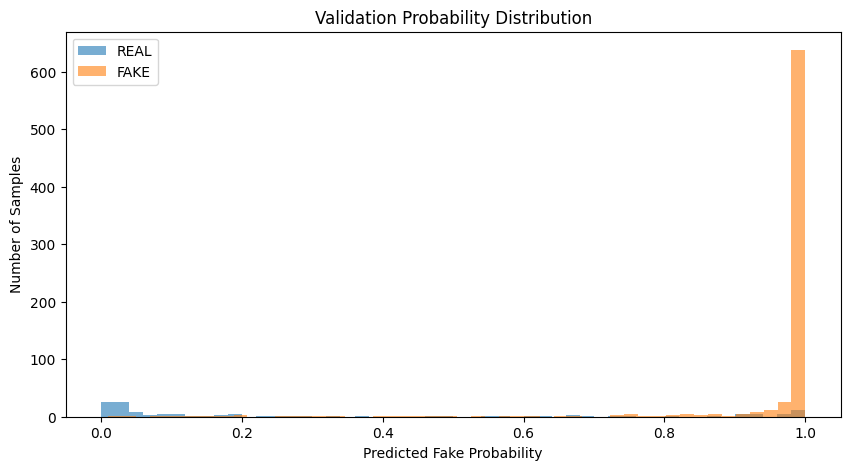

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    all_probs[all_labels == 0],
    bins=50,
    alpha=0.6,
    label="REAL"
)

plt.hist(
    all_probs[all_labels == 1],
    bins=50,
    alpha=0.6,
    label="FAKE"
)

plt.xlabel("Predicted Fake Probability")
plt.ylabel("Number of Samples")
plt.title("Validation Probability Distribution")
plt.legend()
plt.show()

In [ ]:
def plot_confusion_matrix(
    probs,
    labels,
    threshold=0.5
):

    predictions = (
        probs >= threshold
    ).astype(int)

    cm = confusion_matrix(
        labels,
        predictions
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["REAL", "FAKE"]
    )

    fig, ax = plt.subplots(
        figsize=(6, 6)
    )

    disp.plot(
        ax=ax,
        values_format="d"
    )

    ax.set_title(
        f"Confusion Matrix @ threshold={threshold}"
    )

    plt.show()

In [ ]:
def plot_sorted_probabilities(
    probs,
    labels
):

    order = np.argsort(probs)

    sorted_probs = probs[order]
    sorted_labels = labels[order]

    plt.figure(figsize=(12, 5))

    x = np.arange(len(probs))

    real_mask = sorted_labels == 0
    fake_mask = sorted_labels == 1

    plt.scatter(
        x[real_mask],
        sorted_probs[real_mask],
        s=8,
        label="REAL"
    )

    plt.scatter(
        x[fake_mask],
        sorted_probs[fake_mask],
        s=8,
        label="FAKE"
    )

    plt.axhline(
        0.5,
        linestyle="--"
    )

    plt.xlabel(
        "Validation samples sorted by P(FAKE)"
    )

    plt.ylabel(
        "P(FAKE)"
    )

    plt.title(
        "Sorted Validation Predictions"
    )

    plt.legend()
    plt.grid(True)

    plt.show()

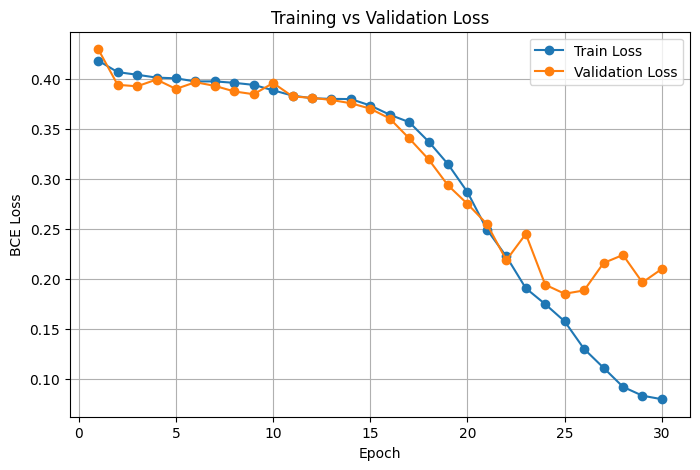

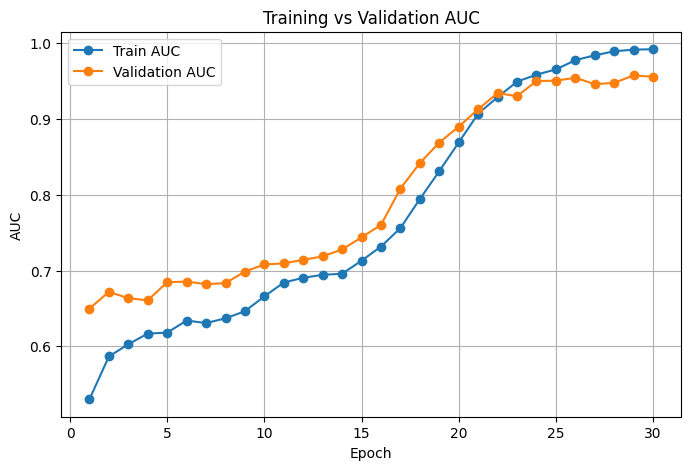

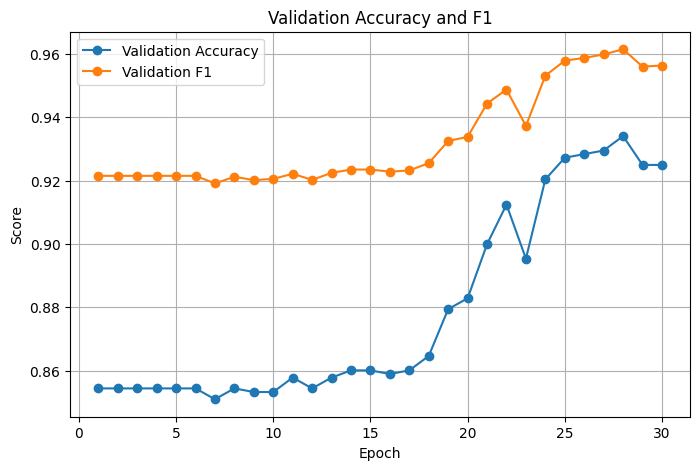

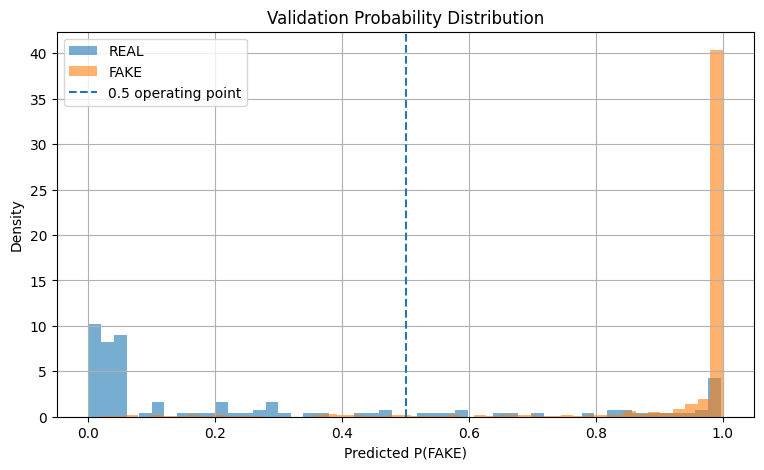

REAL
Mean : 0.2747
Min  : 0.0002
Max  : 0.9967

FAKE
Mean : 0.9436
Min  : 0.0186
Max  : 1.0000


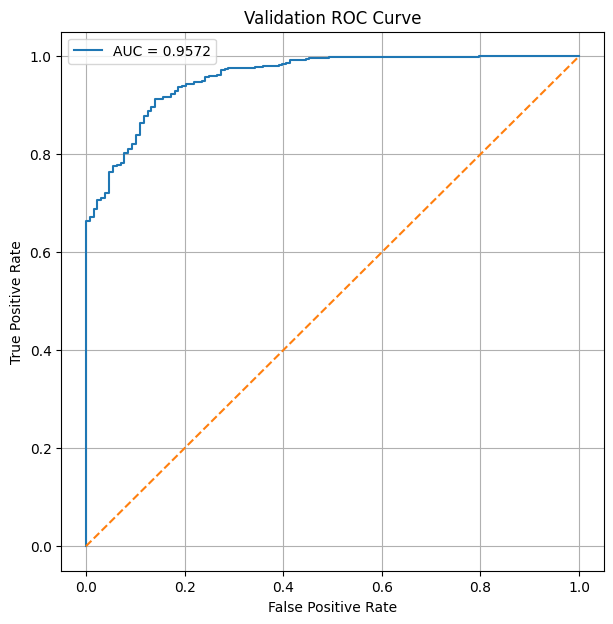

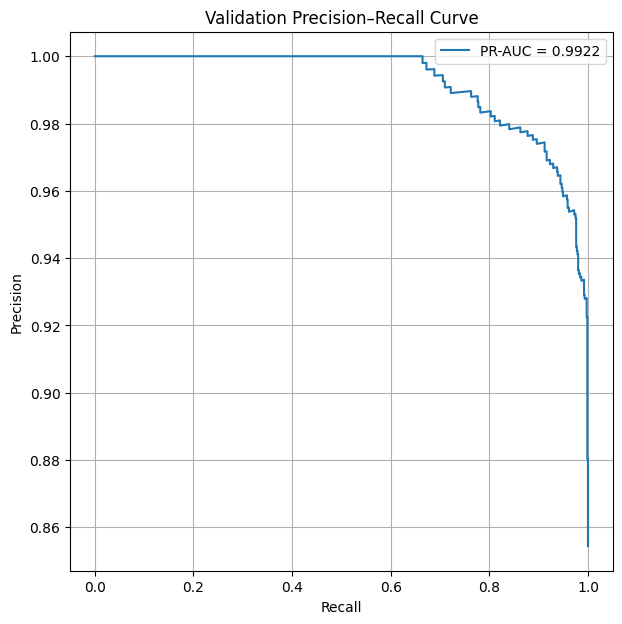

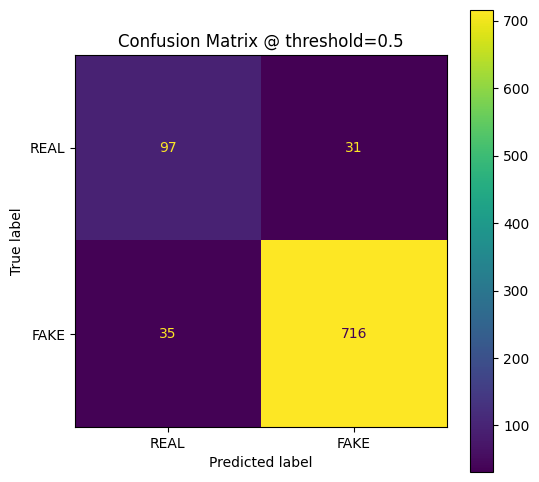

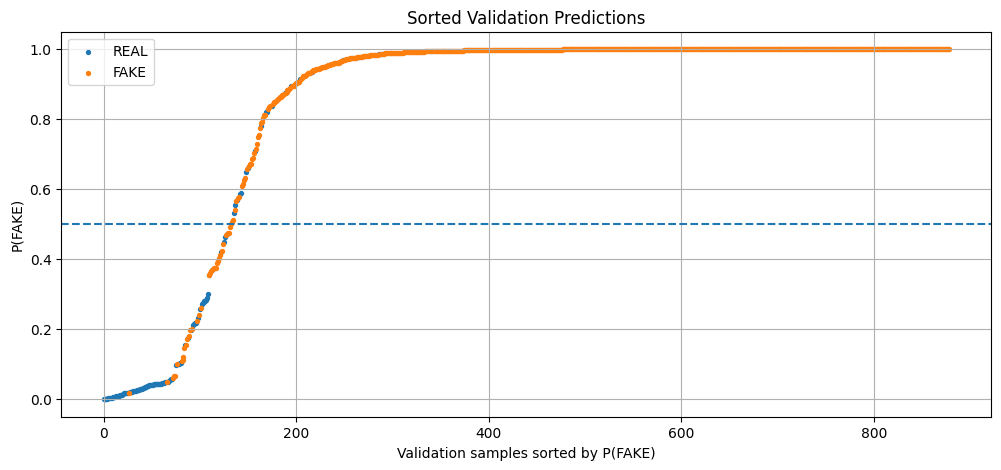

In [ ]:
model.load_state_dict(best_state)
model.to(DEVICE)
final_val = evaluate(
    model,
    val_loader,
    criterion
)
val_probs = final_val["probs"]
val_labels = final_val["labels"]
plot_training_history(history)

plot_probability_distribution(
    val_probs,
    val_labels
)

plot_roc(
    val_probs,
    val_labels
)

plot_pr_curve(
    val_probs,
    val_labels
)

plot_confusion_matrix(
    val_probs,
    val_labels
)
plot_sorted_probabilities(
    val_probs,
    val_labels
)

# 28. Final Test

In [ ]:
# inference latency measurement
print("\n" + "=" * 60)
print("EDGE LATENCY BENCHMARK (SAGE-30 Frames)")
print("=" * 60)

# [Batch=1, Frames=30, Channels=3, H=224, W=224]
dummy_video = torch.randn(1, 30, 3, 224, 224).to(DEVICE)

model.load_state_dict(best_state)
model.eval()

# 1. GPU Warm-up (Crucial for accurate timing)
print("Warming up GPU...")
with torch.no_grad():
    for _ in range(20):
        _ = model(dummy_video)

# 2. Synchronized Timing Setup
starter = torch.cuda.Event(enable_timing=True)
ender = torch.cuda.Event(enable_timing=True)
timings = []
iterations = 100

print(f"Running {iterations} iterations for statistical average...")

with torch.no_grad():
    for _ in range(iterations):
        starter.record()
        _ = model(dummy_video)
        ender.record()

        # Wait for GPU to finish computing
        torch.cuda.synchronize()

        curr_time = starter.elapsed_time(ender)
        timings.append(curr_time)

mean_syn = np.mean(timings)
std_syn = np.std(timings)

print(f"\nFinal SAGE Inference Latency: {mean_syn:.2f} ms ± {std_syn:.2f} ms per video")
print(f"Frames Per Second (FPS): {1000 / mean_syn:.2f} videos/sec")


EDGE LATENCY BENCHMARK (SAGE-30 Frames)
Warming up GPU...
Running 100 iterations for statistical average...

Final SAGE Inference Latency: 146.21 ms ± 2.85 ms per video
Frames Per Second (FPS): 6.84 videos/sec


In [ ]:
model.load_state_dict(
    best_state
)

test_metrics = evaluate(
    model,
    test_loader,
    criterion
)

print("\n" + "=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)

for key, value in test_metrics.items():

    print(
        f"{key:12s}: {value:.4f}"
    )


FINAL TEST RESULTS
loss        : 0.2165
auc         : 0.9484
accuracy    : 0.9199
f1          : 0.9535
precision   : 0.9535
recall      : 0.9535


TypeError: unsupported format string passed to numpy.ndarray.__format__